# Load model and Train

In [3]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import torch
from models.ArrheniusStateSurrogate import ArrheniusStateSurrogate

# ---------------- Load data ----------------
df = pd.read_csv("../data/raw/h2o2_trajectories.csv")
species_cols = [c.replace("Y_", "") for c in df.columns if c.startswith("Y_")]

# ---------------- Build (t, t+dt) pairs WITHIN each trajectory ----------------
def build_pairs(d):
    rows = []
    for traj_id, g in d.groupby("traj_idx"):
        g = g.sort_values("t").reset_index(drop=True)
        for i in range(len(g) - 1):
            rows.append({
                "T": g.loc[i, "T"], "T_next": g.loc[i + 1, "T"],
                "rho": g.loc[i, "rho"],
                "dt": g.loc[i + 1, "t"] - g.loc[i, "t"],
                **{f"Y_{s}": g.loc[i, f"Y_{s}"] for s in species_cols},
                **{f"Y_{s}_next": g.loc[i + 1, f"Y_{s}"] for s in species_cols},
            })
    return pd.DataFrame(rows)

# ---------------- Split by TRAJECTORY first, then build pairs ----------------
traj_ids = df["traj_idx"].unique()
rng = np.random.default_rng(0)
rng.shuffle(traj_ids)
n_val = int(0.2 * len(traj_ids))
val_ids, train_ids = set(traj_ids[:n_val]), set(traj_ids[n_val:])

train_pairs = build_pairs(df[df["traj_idx"].isin(train_ids)])
val_pairs = build_pairs(df[df["traj_idx"].isin(val_ids)])

def to_tensors(d):
    T = torch.tensor(d["T"].to_numpy(), dtype=torch.float32)
    T_next = torch.tensor(d["T_next"].to_numpy(), dtype=torch.float32)
    rho = torch.tensor(d["rho"].to_numpy(), dtype=torch.float32)
    dt = torch.tensor(d["dt"].to_numpy(), dtype=torch.float32)
    Y = torch.tensor(d[[f"Y_{s}" for s in species_cols]].to_numpy(), dtype=torch.float32)
    Y_next = torch.tensor(d[[f"Y_{s}_next" for s in species_cols]].to_numpy(), dtype=torch.float32)
    return T, Y, rho, dt, T_next, Y_next

T_tr, Y_tr, rho_tr, dt_tr, T_next_tr, Y_next_tr = to_tensors(train_pairs)
T_va, Y_va, rho_va, dt_va, T_next_va, Y_next_va = to_tensors(val_pairs)

# ---------------- Model + fit normalization stats on TRAIN only ----------------
gas_mw = None  # reuse mw from earlier cell if already in scope, else recompute:
import cantera as ct
gas = ct.Solution("h2o2.yaml")
mw = np.array([gas.molecular_weights[gas.species_index(s)] for s in species_cols])

model = ArrheniusStateSurrogate(n_species=len(species_cols), molecular_weights=mw)

Y_MIN = model.Y_MIN
logY_all = torch.log(torch.clamp(torch.cat([Y_tr, Y_next_tr], dim=0), min=Y_MIN))
logdt_all = torch.log(torch.clamp(dt_tr, min=1e-12))
dT_all = T_next_tr - T_tr

model.set_norm_stats(
    logY_mean=logY_all.mean(dim=0), logY_std=logY_all.std(dim=0),
    T_mean=torch.cat([T_tr, T_next_tr]).mean(), T_std=torch.cat([T_tr, T_next_tr]).std(),
    logdt_mean=logdt_all.mean(), logdt_std=logdt_all.std(),
    dT_std=dT_all.std(),
)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)

# ---------------- Train ----------------
n_epochs = 200
batch_size = 512
n_train = T_tr.shape[0]

train_losses, val_losses, val_epochs = [], [], []

for epoch in range(n_epochs):
    perm = torch.randperm(n_train)
    total_loss = 0.0
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]

        T_next_pred, Y_next_pred, info = model(T_tr[idx], Y_tr[idx], rho_tr[idx], dt_tr[idx])

        # loss in NORMALIZED state space -- same fix as before
        Tn_pred = model.normalize_T(T_next_pred)
        Tn_true = model.normalize_T(T_next_tr[idx])
        logYn_pred = model.normalize_Y(Y_next_pred)
        logYn_true = model.normalize_Y(Y_next_tr[idx])

        loss = torch.nn.functional.mse_loss(Tn_pred, Tn_true) \
             + torch.nn.functional.mse_loss(logYn_pred, logYn_true)

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # smooths the loss spikes we saw before
        opt.step()
        total_loss += loss.item() * len(idx)

    train_losses.append(total_loss / n_train)

    if epoch % 10 == 0:
        with torch.no_grad():
            T_next_pred_v, Y_next_pred_v, info_v = model(T_va, Y_va, rho_va, dt_va)
            Tn_pred_v = model.normalize_T(T_next_pred_v)
            Tn_true_v = model.normalize_T(T_next_va)
            logYn_pred_v = model.normalize_Y(Y_next_pred_v)
            logYn_true_v = model.normalize_Y(Y_next_va)
            val_loss = torch.nn.functional.mse_loss(Tn_pred_v, Tn_true_v) \
                     + torch.nn.functional.mse_loss(logYn_pred_v, logYn_true_v)
        val_losses.append(val_loss.item())
        val_epochs.append(epoch)
        print(f"epoch {epoch:4d}  train {total_loss/n_train:.4f}  val {val_loss.item():.4f}")

epoch    0  train 89117369689106.6250  val 0.0148
epoch   10  train 0.0204  val 0.0143
epoch   20  train 0.0139  val 0.0082
epoch   30  train 0.0104  val 0.0076
epoch   40  train 0.0080  val 0.0062
epoch   50  train 0.0070  val 0.0056
epoch   60  train 0.0069  val 0.0055
epoch   70  train 0.0069  val 0.0054
epoch   80  train 0.0065  val 0.0054
epoch   90  train 0.0065  val 0.0055
epoch  100  train 0.0068  val 0.0054
epoch  110  train 0.0065  val 0.0054
epoch  120  train 0.0064  val 0.0053
epoch  130  train 0.0065  val 0.0054
epoch  140  train 0.0065  val 0.0055
epoch  150  train 0.0116  val 0.0065
epoch  160  train 0.0066  val 0.0053
epoch  170  train 0.0066  val 0.0054
epoch  180  train 0.0064  val 0.0053
epoch  190  train 0.0064  val 0.0053


NameError: name 'train_losses' is not defined

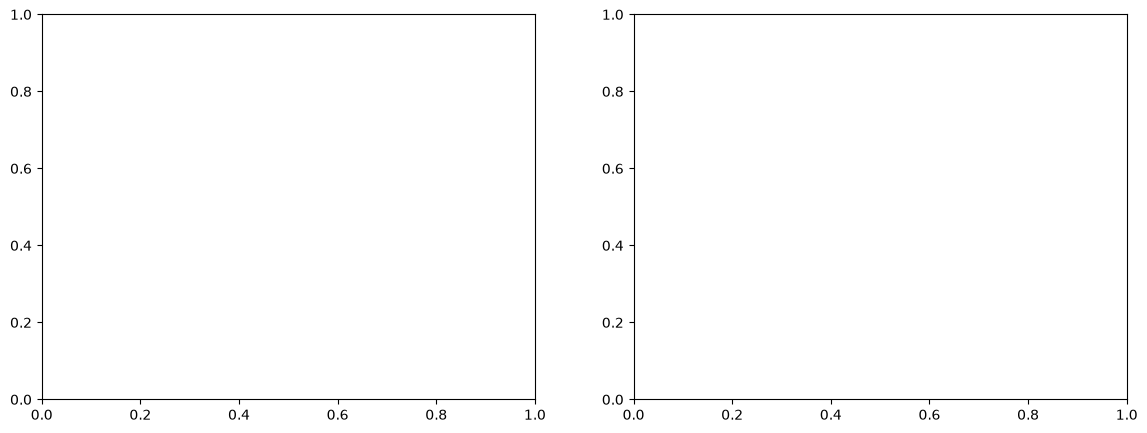

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Learning curve ----
axes[0].plot(train_losses, label="train")
axes[0].plot(val_epochs, val_losses, label="val", marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE loss (normalized space)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Learning curve")

# ---- Rollout on one held-out trajectory ----
traj_id = list(val_ids)[0]
traj = df[df["traj_idx"] == traj_id].sort_values("t").reset_index(drop=True)

T0 = torch.tensor([traj.loc[0, "T"]], dtype=torch.float32)
Y0 = torch.tensor([[traj.loc[0, f"Y_{s}"] for s in species_cols]], dtype=torch.float32)
t_arr = traj["t"].to_numpy()
rho_arr = traj["rho"].to_numpy()   # true density trajectory -- fed in, not predicted

T_rollout = [T0.item()]
Y_rollout = [Y0.numpy()[0]]

T_cur, Y_cur = T0, Y0
with torch.no_grad():
    for i in range(len(t_arr) - 1):
        dt = torch.tensor([t_arr[i + 1] - t_arr[i]], dtype=torch.float32)
        rho_cur = torch.tensor([rho_arr[i]], dtype=torch.float32)   # rho at the CURRENT step, matches training pairs
        T_cur, Y_cur, _ = model(T_cur, Y_cur, rho_cur, dt)
        T_rollout.append(T_cur.item())
        Y_rollout.append(Y_cur.numpy()[0])

T_rollout = np.array(T_rollout)
Y_rollout = np.array(Y_rollout)
Y_true = traj[[f"Y_{s}" for s in species_cols]].to_numpy()

fig2, axes2 = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
axes2[0].plot(t_arr, traj["T"], label="true", color="black")
axes2[0].plot(t_arr, T_rollout, label="pred (rollout)", color="red", linestyle="--")
axes2[0].set_ylabel("T [K]")
axes2[0].set_xscale("log")
axes2[0].legend()

n_show = min(6, len(species_cols))
for i in range(n_show):
    axes2[1].plot(t_arr, Y_true[:, i], color=f"C{i}", label=species_cols[i])
    axes2[1].plot(t_arr, Y_rollout[:, i], color=f"C{i}", linestyle="--")
axes2[1].set_xlabel("t [s]")
axes2[1].set_ylabel("Y")
axes2[1].set_yscale("log")
axes2[1].set_xscale("log")
axes2[1].legend(fontsize=7, ncol=3)

plt.tight_layout()
plt.show()